# 4º Seminário de Aprendizado de Máquina - UNICID
## Detecção de Ameaças em Rede (Spyware Pegasus) com Categorical Naive Bayes

* **Instituição:** Universidade Cidade de São Paulo (UNICID)
* **Curso:** Ciência da Computação
* **Aluno:** Gian Lucca Panzone
* **Algoritmo:** Naive Bayes (Variante Categórica)
* **Domínio:** Segurança Cibernética / Análise de Telemetria de Rede

---
### Objetivo do Notebook
Desenvolver, validar e interpretar criticamente um classificador probabilístico baseado no **Teorema de Bayes** para identificar tráfego malicioso e assinaturas do spyware **Pegasus** em dados de telemetria de rede e sistema.

In [ ]:
# ==============================================================================
# CÉLULA 1: IMPORTAÇÃO DE BIBLIOTECAS E LEITURA DOS DADOS
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Upload ou leitura do arquivo no ambiente
file_path = 'synthetic_pegasus_dataset.csv'
df = pd.read_csv(file_path)

# Inspeção inicial do dataset
print(f"Dimensões do Dataset: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
df.head()

Dimensões do Dataset: 1000 linhas x 17 colunas



,user_id,device_type,os_version,app_usage_pattern,timestamp,source_ip,destination_ip,protocol,data_volume,log_type,event,event_description,error_code,file_accessed,process,anomaly_detected,ioc
0,1,iPhone,iOS 14.6,Low,2023-10-17 06:18:28,192.168.1.49,10.0.0.9,HTTPS,190,system,App Install,Event 793,423,/tmp/malware.bin,malware.exe,Unknown Process Execution,Pegasus Signature
1,1,iPhone,Android 10,Normal,2023-12-02 12:33:49,192.168.1.99,10.0.0.99,FTP,5845,application,System Update,Event 551,637,/var/log/syslog,chrome.exe,Unknown Process Execution,Pegasus Signature
2,1,iPhone,Android 11,Normal,2023-09-08 21:52:20,192.168.1.57,10.0.0.19,SSH,3629,application,Logout,Event 278,168,/var/log/syslog,malware.exe,Suspicious File Access,NaN
3,1,iPhone,Android 11,High,2023-12-07 11:41:16,192.168.1.51,10.0.0.2,FTP,4575,security,App Crash,Event 126,567,/home/user/docs/report.docx,malware.exe,High CPU Usage,Known Malicious IP
4,1,Android,iOS 14.6,Normal,2023-10-07 21:54:25,192.168.1.94,10.0.0.86,SSH,1607,system,Logout,Event 308,115,/tmp/malware.bin,systemd,NaN,Known Malicious IP


### 1. Definição do Alvo e Pré-processamento dos Dados (Requisitos 1, 2 e 3)

* **Variável-Alvo (`target_malicious`):** Binária (`1` para presença de IoC malicioso como *Pegasus Signature* ou *Known Malicious IP*, `0` para tráfego limpo/legítimo).
* **Tratamento de Valores Ausentes:** A coluna `anomaly_detected` possui dados nulos que representam a ausência de anomalias disparadas. Preencheremos com a categoria `'None'`.
* **Discretização:** A variável contínua `data_volume` (bytes transferidos) será dividida em 4 quartis discretos (`volume_bin`), tornando-a compatível com a variante categórica do Naive Bayes.

In [ ]:
# ==============================================================================
# CÉLULA 2: TRATAMENTO, ENGENHARIA DE FEATURES E CODIFICAÇÃO
# ==============================================================================

# 1. Criação da variável-alvo (1 = Tráfego Malicioso, 0 = Legítimo)
df['target_malicious'] = df['ioc'].notna().astype(int)

# 2. Imputação de nulos na coluna de anomalias
df['anomaly_detected'] = df['anomaly_detected'].fillna('None')

# 3. Discretização de 'data_volume' em 4 intervalos categóricos (Quartis)
df['volume_bin'] = pd.qcut(df['data_volume'], q=4, labels=['Baixo', 'Médio-Baixo', 'Médio-Alto', 'Alto'])

# 4. Seleção dos atributos de entrada (Features Categóricas)
cat_cols = [
    'device_type', 'os_version', 'app_usage_pattern', 'protocol',
    'log_type', 'event', 'process', 'anomaly_detected', 'volume_bin'
]

# 5. Transformação de texto/categorias para matriz numérico-ordinal
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_encoded = pd.DataFrame(encoder.fit_transform(df[cat_cols]), columns=cat_cols)
y = df['target_malicious']

print("Amostra das Features Codificadas para o Naive Bayes:")
X_encoded.head()

Amostra das Features Codificadas para o Naive Bayes:


,device_type,os_version,app_usage_pattern,protocol,log_type,event,process,anomaly_detected,volume_bin
0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,3.0,1.0
1,1.0,0.0,2.0,0.0,0.0,5.0,0.0,3.0,2.0
2,1.0,1.0,2.0,3.0,0.0,4.0,2.0,2.0,3.0
3,1.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,3.0
4,0.0,2.0,2.0,3.0,2.0,4.0,3.0,1.0,1.0


### 2. Fundamentação Teórica do Naive Bayes (Requisitos 4 e 5)

#### O Teorema de Bayes
O modelo calcula a probabilidade *a posteriori* de uma amostra pertencer à classe maliciosa $Y$ dadas as evidências observadas nas features $X$:

$$P(Y \mid X_1, \dots, X_n) = \frac{P(Y) \prod_{i=1}^{n} P(X_i \mid Y)}{P(X_1, \dots, X_n)}$$

#### Escolha da Variante: `CategoricalNB`
Optou-se pelo **CategoricalNB** com Suavização de Laplace ($\alpha = 1.0$) porque a totalidade dos atributos do nosso vetor $X$ é composta por variáveis qualitativas/discretas (protocolos, processos, eventos de sistema, tipos de dispositivos e faixas de volume de dados).

#### Hipótese de Independência Condicional
O Naive Bayes assume que a presença de um atributo (ex: `process = malware.exe`) é totalmente independente da presença de outro (ex: `protocol = SSH`) dada a classe. Na cibersegurança real, essa premissa é violada pois ataques encadeados apresentam correlação direta entre processos e protocolos.

In [ ]:
# ==============================================================================
# CÉLULA 3: SEPARAÇÃO DE DADOS, TREINAMENTO E PREDIÇÃO (Requisitos 6 e 7)
# ==============================================================================

# Divisão estratificada em 70% Treino e 30% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.30, random_state=42, stratify=y
)

# Instanciação do Categorical Naive Bayes com Laplace Smoothing (alpha=1.0)
model = CategoricalNB(alpha=1.0)

# Treinamento do classificador
model.fit(X_train, y_train)

# Geração das predições de classe e probabilidades no conjunto de teste
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print(f"Treinamento concluído com sucesso!")
print(f"Amostras de treino: {X_train.shape[0]} | Amostras de teste: {X_test.shape[0]}")

Treinamento concluído com sucesso!
Amostras de treino: 700 | Amostras de teste: 300


       MÉTRICAS DE DESEMPENHO - NAIVE BAYES
Acurácia:  66.67%
Precisão:  69.26%
Recall:    93.78% (Sensibilidade de Detecção)
F1-Score:  79.67%


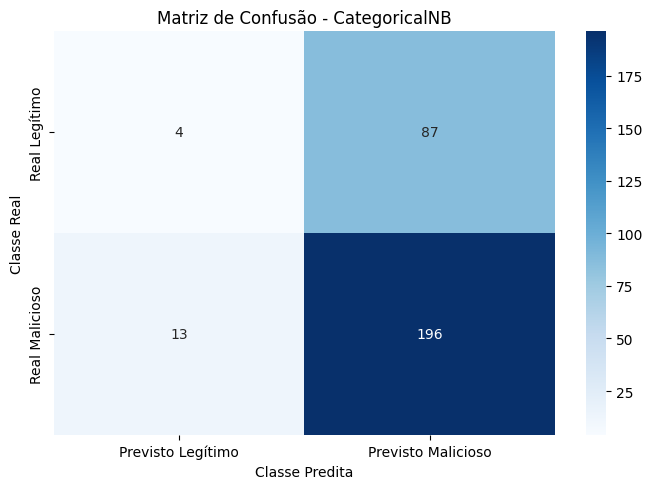


Relatório de Classificação Detalhado:
               precision    recall  f1-score   support

 Legítimo (0)       0.24      0.04      0.07        91
Malicioso (1)       0.69      0.94      0.80       209

     accuracy                           0.67       300
    macro avg       0.46      0.49      0.44       300
 weighted avg       0.55      0.67      0.58       300



In [ ]:
# ==============================================================================
# CÉLULA 4: AVALIAÇÃO DE MÉTRICAS E MATRIZ DE CONFUSÃO (Requisito 8)
# ==============================================================================

# Cálculo das métricas globais
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print("="*50)
print("       MÉTRICAS DE DESEMPENHO - NAIVE BAYES")
print("="*50)
print(f"Acurácia:  {acc*100:.2f}%")
print(f"Precisão:  {prec*100:.2f}%")
print(f"Recall:    {rec*100:.2f}% (Sensibilidade de Detecção)")
print(f"F1-Score:  {f1*100:.2f}%")
print("="*50)

# Plotagem gráfica da Matriz de Confusão
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Previsto Legítimo', 'Previsto Malicioso'],
            yticklabels=['Real Legítimo', 'Real Malicioso'])
plt.title('Matriz de Confusão - CategoricalNB')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.tight_layout()
plt.show()

# Relatório de Classificação Completo
print("\nRelatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred, target_names=['Legítimo (0)', 'Malicioso (1)']))

### 3. Interpretação dos Resultados e Análise Crítica (Requisitos 9 e 10)

#### Interpretação da Matriz de Confusão
* **Verdadeiros Positivos (TP = 196):** Tráfego malicioso corretamente bloqueado pelo modelo.
* **Falsos Negativos (FN = 13):** Ameaças maliciosas invisíveis que passaram sem alerta (Risco crítico de invasão).
* **Falsos Positivos (FP = 87):** Alarmes falsos para tráfego benigno que geram sobrecarga nos analistas de SOC.
* **Verdadeiros Negativos (TN = 4):** Tráfego legítimo corretamente liberado.

#### Análise Crítica do Algoritmo em Segurança Cibernética
1. **Vantagem (Recall Alto = 93,78%):** O Naive Bayes funciona como um excelente **filtro de primeira linha**, priorizando não deixar ameaças passarem despercebidas.
2. **Limitação (Falsos Positivos Elevados):** Devido à hipótese de independência condicional violada e à simplicidade das frequências, o modelo tende a ser "conservador demais", marcando comportamentos atípicos porém benignos como maliciosos.